# ARIMA Multi-Horizon Baseline — JalVaani

Fits **ARIMA(7,1,1)** per district on daily GWL data.

**Rolling evaluation** with monthly refit (every 30 steps). At each step forecasts
h = **7, 14, 30** days ahead simultaneously, matching predictions against actual future values.

> Run this notebook **after** executing `01_arima_sarima.ipynb` (t+1 baseline).
> Outputs go to `outputs/`; plots to `outputs/plots/`.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from statsmodels.tsa.arima.model import ARIMA
from tqdm.auto import tqdm
from IPython.display import display

warnings.filterwarnings('ignore')
%matplotlib inline
plt.rcParams['figure.dpi'] = 130
plt.rcParams['font.size']  = 11

MASTER   = Path('../../Data Preprocessing/clean datasets/master_dataset.csv')
OUT_DIR  = Path('outputs')
PLOT_DIR = OUT_DIR / 'plots'
OUT_DIR.mkdir(exist_ok=True)
PLOT_DIR.mkdir(exist_ok=True)

TRAIN_END    = pd.Timestamp('2024-09-30')
VAL_END      = pd.Timestamp('2025-01-31')
HORIZONS     = [7, 14, 30]
ORDER        = (7, 1, 1)
MIN_TRAIN    = 90
REFIT_EVERY  = 30

COLORS = {7: '#e41a1c', 14: '#ff7f00', 30: '#377eb8'}

print('Config loaded ✓')
print(f'  ARIMA order  : {ORDER}')
print(f'  Horizons     : {HORIZONS}')
print(f'  Refit every  : {REFIT_EVERY} steps')

Config loaded ✓
  ARIMA order  : (7, 1, 1)
  Horizons     : [7, 14, 30]
  Refit every  : 30 steps


## 1. Load Data

In [2]:
df = pd.read_csv(MASTER, parse_dates=['date'])
df = df.sort_values(['district', 'date']).reset_index(drop=True)
print(f'Loaded: {len(df):,} rows | {df["district"].nunique()} districts')
print(f'Date range: {df["date"].min().date()} → {df["date"].max().date()}')
print(f'GWL range : {df["gwl_mean"].min():.2f}m → {df["gwl_mean"].max():.2f}m')

Loaded: 16,785 rows | 24 districts
Date range: 2023-03-02 → 2025-04-22
GWL range : -98.98m → -0.21m


## 2. Rolling Multi-Horizon Forecast

In [3]:
def fill_series(s):
    return s.interpolate('linear').bfill().ffill()

def compute_metrics(actual, pred):
    a, p = np.array(actual, float), np.array(pred, float)
    valid = ~(np.isnan(a) | np.isnan(p))
    a, p  = a[valid], p[valid]
    if len(a) == 0: return np.nan, np.nan, np.nan
    rmse = np.sqrt(np.mean((a-p)**2))
    mae  = np.mean(np.abs(a-p))
    mask = a != 0
    mape = np.mean(np.abs((a[mask]-p[mask])/a[mask]))*100 if mask.any() else np.nan
    return rmse, mae, mape

all_rows  = []
skip_list = []

districts = sorted(df['district'].unique())
print(f'Running rolling ARIMA for {len(districts)} districts...\n')

for dist in tqdm(districts, desc='ARIMA multi-horizon'):
    sub = (
        df[df['district'] == dist][['date', 'gwl_mean']]
        .set_index('date').sort_index().asfreq('D')
    )
    train_s = sub.loc[sub.index <= TRAIN_END, 'gwl_mean']
    val_s   = sub.loc[(sub.index > TRAIN_END) & (sub.index <= VAL_END), 'gwl_mean']
    test_s  = sub.loc[sub.index > VAL_END, 'gwl_mean']

    if train_s.notna().sum() < MIN_TRAIN:
        skip_list.append(dist)
        continue

    history = list(fill_series(train_s).values)

    try:
        cur_model = ARIMA(np.array(history), order=ORDER).fit(
            method_kwargs={'warn_convergence': False})
    except Exception as e:
        tqdm.write(f'  ✗ {dist}: {e}')
        skip_list.append(dist)
        continue

    last_refit_step = 0
    fc_cache        = None
    combined        = pd.concat([val_s, test_s])

    for i, (date, obs) in enumerate(combined.items()):
        split_name        = 'val' if date <= VAL_END else 'test'
        steps_since_refit = i - last_refit_step

        if fc_cache is None:
            fc_len   = REFIT_EVERY + max(HORIZONS) + 1
            try:    fc_cache = cur_model.forecast(steps=fc_len)
            except: fc_cache = np.full(fc_len, np.nan)

        for h in HORIZONS:
            fc_idx = steps_since_refit + h - 1
            if fc_idx >= len(fc_cache): continue
            pred_val    = float(fc_cache[fc_idx])
            future_date = date + pd.Timedelta(days=h)
            if future_date in sub.index:
                actual_h = sub.loc[future_date, 'gwl_mean']
                if not pd.isna(actual_h) and not np.isnan(pred_val):
                    all_rows.append({
                        'district':   dist,
                        'date':       future_date,
                        'horizon':    h,
                        'gwl_actual': float(actual_h),
                        'gwl_pred':   pred_val,
                        'split':      split_name,
                    })

        obs_val = float(obs) if not pd.isna(obs) else history[-1]
        history.append(obs_val)

        if (i - last_refit_step + 1) >= REFIT_EVERY:
            try:
                cur_model = ARIMA(np.array(history), order=ORDER).fit(
                    start_params=cur_model.params,
                    method_kwargs={'warn_convergence': False})
            except:
                try:  cur_model = ARIMA(np.array(history), order=ORDER).fit(
                    method_kwargs={'warn_convergence': False})
                except: pass
            last_refit_step = i + 1
            fc_cache        = None

print(f'\nSkipped districts ({len(skip_list)}): {skip_list}')
out_df = pd.DataFrame(all_rows)
print(f'Total prediction records: {len(out_df):,}')

Running rolling ARIMA for 24 districts...



ARIMA multi-horizon:   0%|          | 0/24 [00:00<?, ?it/s]


Skipped districts (0): []
Total prediction records: 13,239


## 3. Save Predictions & Metrics

In [4]:
rows = []
for h in HORIZONS:
    sub_h = out_df[out_df['horizon'] == h]
    sub_h.to_csv(OUT_DIR / f'arima_multihorizon_t{h}.csv', index=False)
    for split in ['val', 'test']:
        s = sub_h[sub_h['split'] == split]
        r, m, mp = compute_metrics(s['gwl_actual'], s['gwl_pred'])
        rows.append({'Model': 'ARIMA', 'Horizon': f't+{h}', 'Split': split,
                     'RMSE': round(r,4), 'MAE': round(m,4), 'MAPE': round(mp,2)})
        print(f'  t+{h:<2d} {split:<4} | RMSE={r:.4f}m  MAE={m:.4f}m  MAPE={mp:.2f}%')

metrics_df = pd.DataFrame(rows)
metrics_df.to_csv(OUT_DIR / 'arima_multihorizon_metrics.csv', index=False)

print('\nPrediction files saved:')
for h in HORIZONS:
    n = len(out_df[out_df['horizon'] == h])
    print(f'  arima_multihorizon_t{h}.csv  ({n:,} rows)')

  t+7  val  | RMSE=5.1477m  MAE=1.6367m  MAPE=30.46%
  t+7  test | RMSE=4.9449m  MAE=2.0134m  MAPE=13.27%
  t+14 val  | RMSE=5.3877m  MAE=1.8730m  MAPE=30.71%
  t+14 test | RMSE=5.1334m  MAE=2.2075m  MAPE=14.12%
  t+30 val  | RMSE=5.8960m  MAE=2.4677m  MAPE=31.19%
  t+30 test | RMSE=5.0997m  MAE=2.4836m  MAPE=15.17%

Prediction files saved:
  arima_multihorizon_t7.csv  (4,653 rows)
  arima_multihorizon_t14.csv  (4,485 rows)
  arima_multihorizon_t30.csv  (4,101 rows)


## 4. Plot: RMSE Degradation Across Horizons

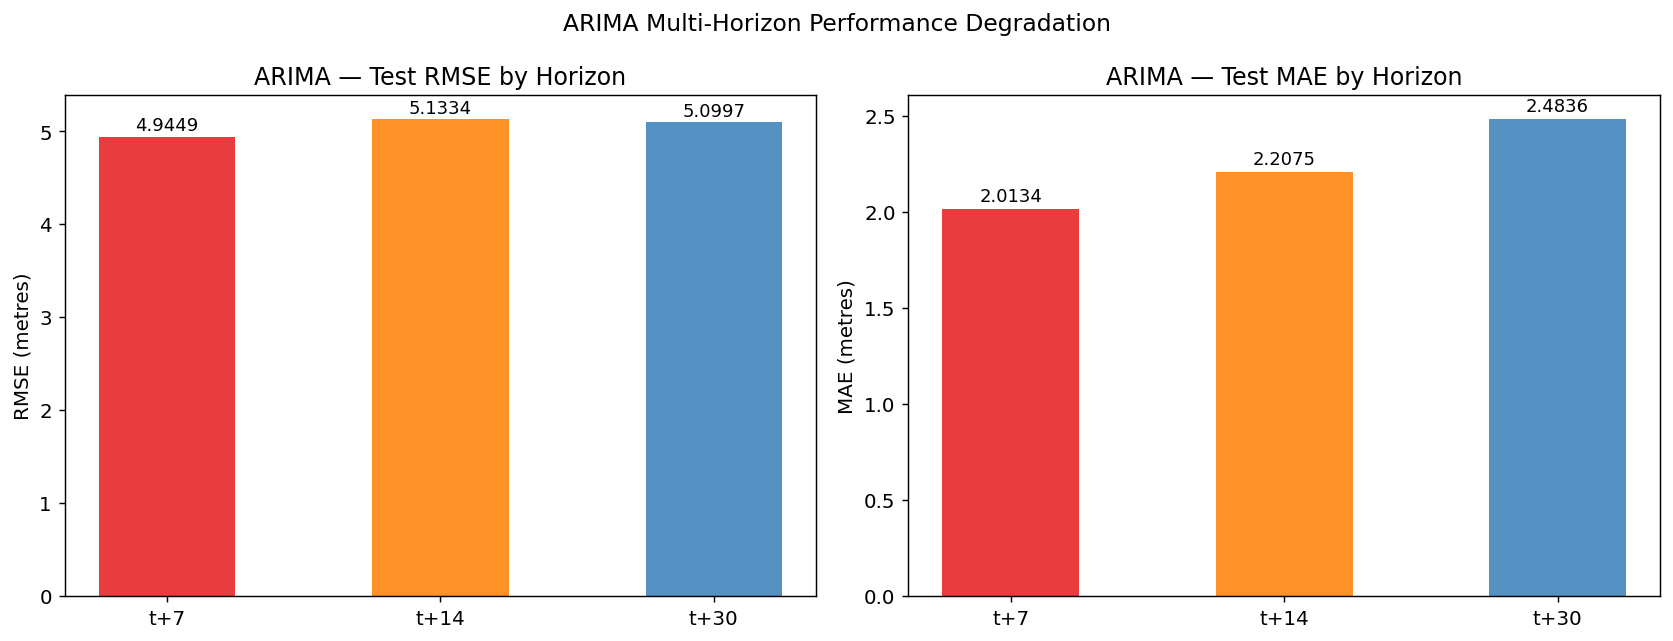

In [5]:
test_metrics = metrics_df[metrics_df['Split'] == 'test']

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# RMSE per horizon
bars = axes[0].bar(
    [f't+{h}' for h in HORIZONS],
    test_metrics['RMSE'].values,
    color=[COLORS[h] for h in HORIZONS], alpha=0.85, width=0.5
)
for bar in bars:
    axes[0].text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.02,
                 f'{bar.get_height():.4f}', ha='center', va='bottom', fontsize=10)
axes[0].set_title('ARIMA — Test RMSE by Horizon')
axes[0].set_ylabel('RMSE (metres)')

# MAE per horizon
bars2 = axes[1].bar(
    [f't+{h}' for h in HORIZONS],
    test_metrics['MAE'].values,
    color=[COLORS[h] for h in HORIZONS], alpha=0.85, width=0.5
)
for bar in bars2:
    axes[1].text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.02,
                 f'{bar.get_height():.4f}', ha='center', va='bottom', fontsize=10)
axes[1].set_title('ARIMA — Test MAE by Horizon')
axes[1].set_ylabel('MAE (metres)')

plt.suptitle('ARIMA Multi-Horizon Performance Degradation', fontsize=13)
plt.tight_layout()
plt.savefig(PLOT_DIR / 'arima_multihorizon_degradation.png', dpi=150)
plt.show()

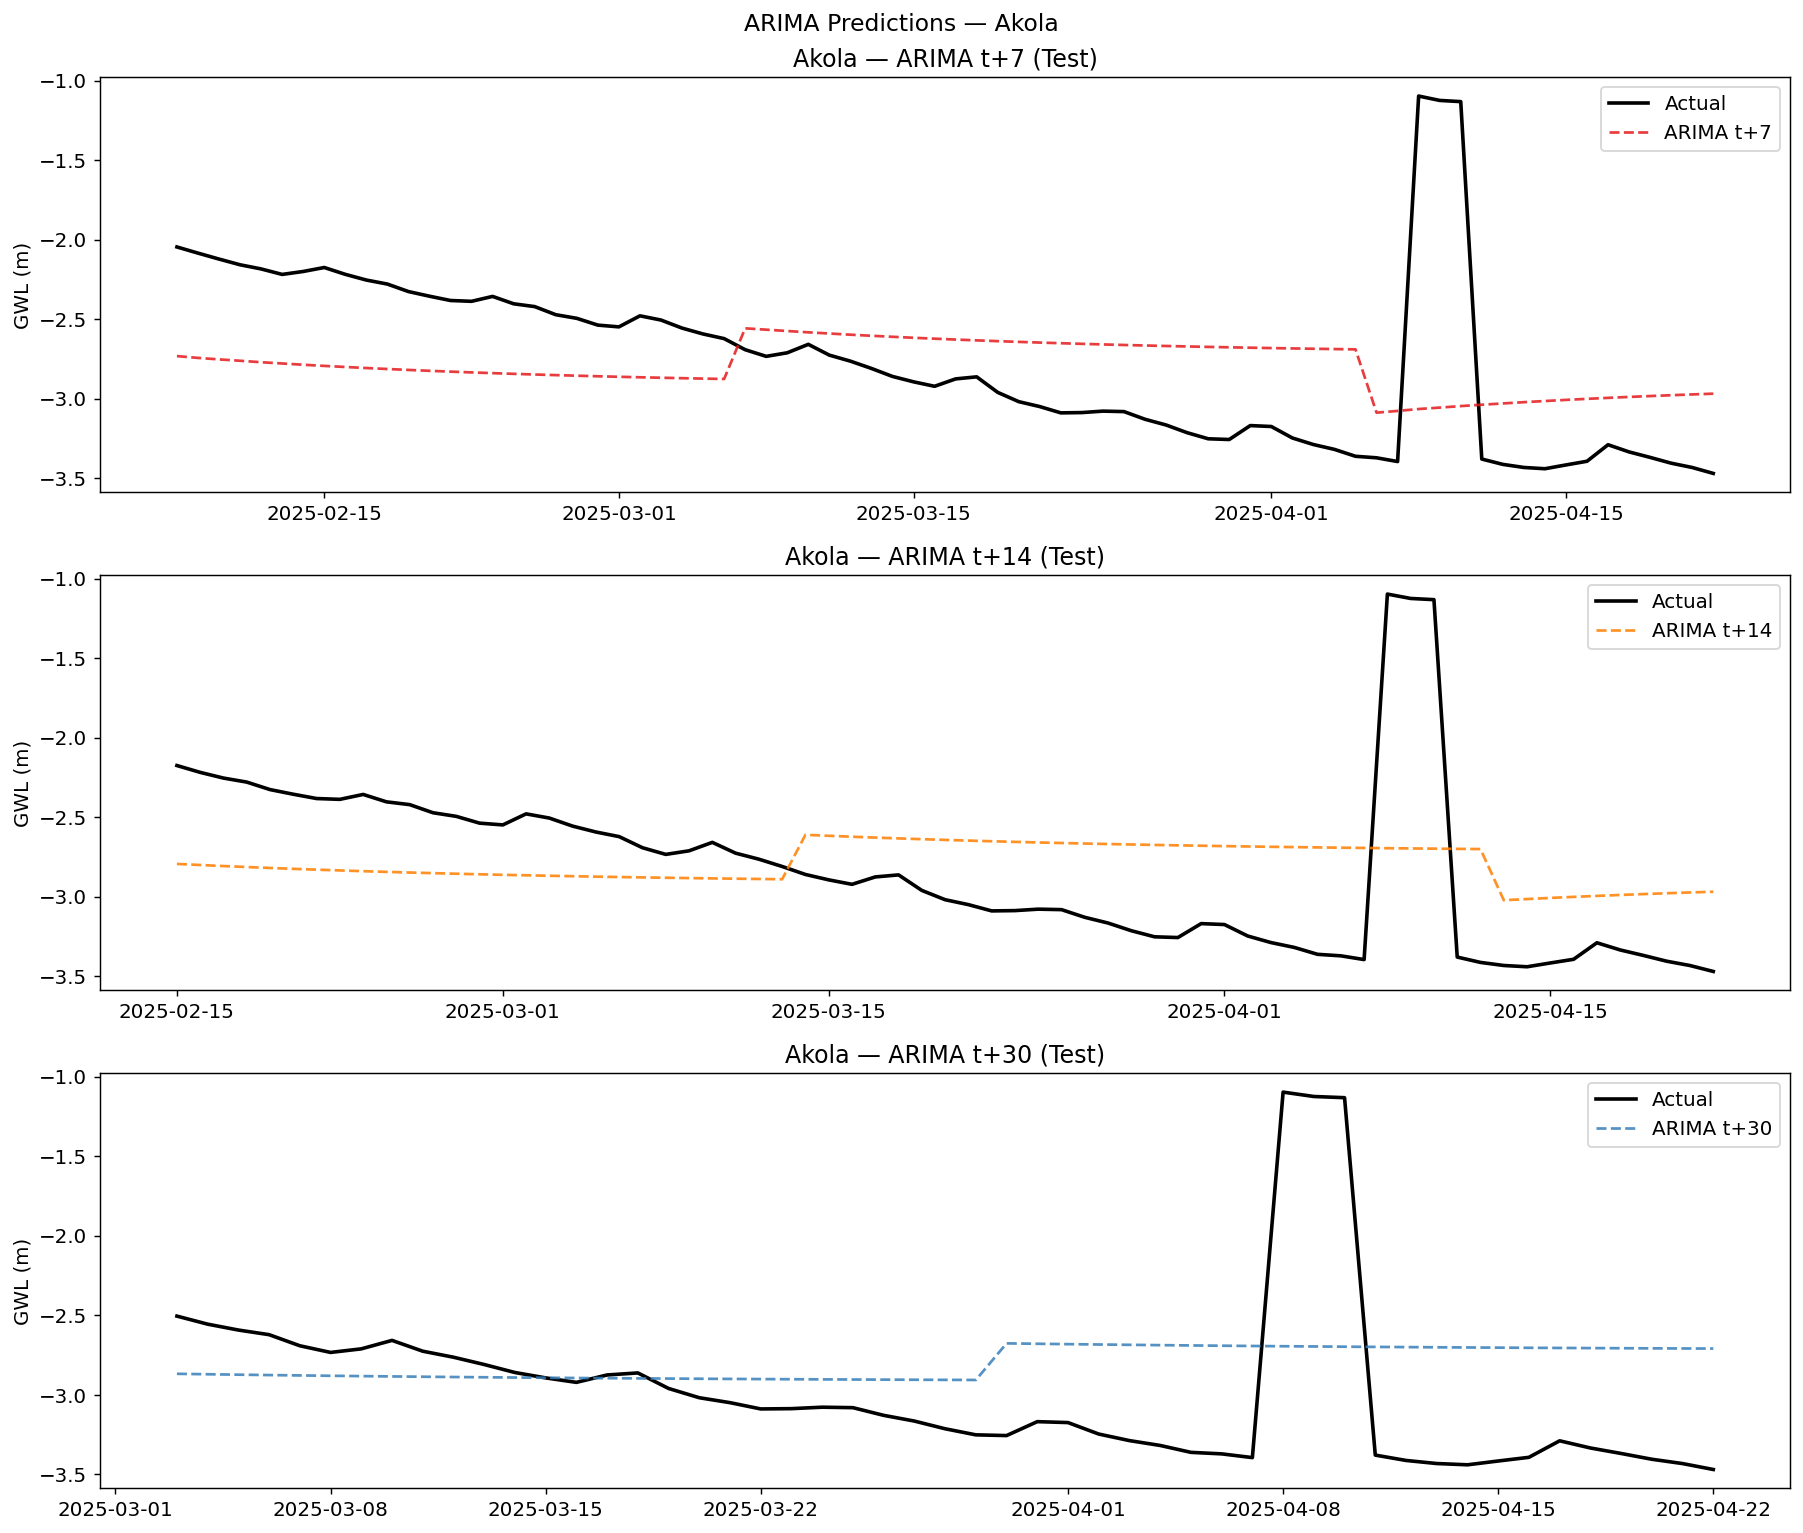

Overlay plot saved for district: Akola


In [6]:
# Prediction overlay for one district — compare all 3 horizons vs actual
test_sub = out_df[out_df['split'] == 'test']
if 'district' in test_sub.columns:
    # Pick district with most predictions
    plot_dist = test_sub.groupby('district').size().idxmax()
    
    fig, axes = plt.subplots(len(HORIZONS), 1, figsize=(14, 4*len(HORIZONS)), sharex=False)
    for ax, h in zip(axes, HORIZONS):
        sub = test_sub[(test_sub['district'] == plot_dist) & (test_sub['horizon'] == h)].copy()
        sub['date'] = pd.to_datetime(sub['date'])
        sub = sub.sort_values('date')
        ax.plot(sub['date'], sub['gwl_actual'], label='Actual', color='black', linewidth=2)
        ax.plot(sub['date'], sub['gwl_pred'],   label=f'ARIMA t+{h}',
                color=COLORS[h], linewidth=1.5, linestyle='--', alpha=0.85)
        ax.set_title(f'{plot_dist} — ARIMA t+{h} (Test)')
        ax.set_ylabel('GWL (m)')
        ax.legend()
    
    plt.suptitle(f'ARIMA Predictions — {plot_dist}', fontsize=13)
    plt.tight_layout()
    plt.savefig(PLOT_DIR / 'arima_multihorizon_overlay.png', dpi=150)
    plt.show()
    print(f'Overlay plot saved for district: {plot_dist}')

## 5. Summary Table

In [7]:
print('=== ARIMA Multi-Horizon Final Summary (Test Set) ===')
display(
    test_metrics[['Horizon','RMSE','MAE','MAPE']]
    .style
    .background_gradient(subset=['RMSE','MAE','MAPE'], cmap='YlOrRd')
    .format({'RMSE': '{:.4f}', 'MAE': '{:.4f}', 'MAPE': '{:.2f}'})
)
print(f'\nNote: {len(skip_list)} districts skipped (insufficient training data)')

=== ARIMA Multi-Horizon Final Summary (Test Set) ===


,Horizon,RMSE,MAE,MAPE
1,t+7,4.9449,2.0134,13.27
3,t+14,5.1334,2.2075,14.12
5,t+30,5.0997,2.4836,15.17



Note: 0 districts skipped (insufficient training data)
